# Лабораторная работа 7
## Кластеризация

200 покупателей торгового центра: пол, возраст, доход, spending score. Готовой метки сегмента нет.

K-means двигает центры групп. Иерархическая кластеризация сливает ближайшие кучи. DBSCAN ищет плотные сгустки и может пометить одиночек как шум (−1). Число групп берётся по локтю инерции. PCA и t-SNE только рисуют уже найденные группы.


In [1]:
%matplotlib inline
# -*- coding: utf-8 -*-
"""
Лабораторная работа 7 — кластеризация.
Данные: Mall Customers Segmentation (200 покупателей).

Запуск: python lab7/lab7.py
Графики: lab7/figures/
"""

from pathlib import Path
import zipfile

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder, StandardScaler

ROOT = Path.cwd()
if not (ROOT / 'lab7.py').exists() and (ROOT / 'lab7').is_dir():
    ROOT = ROOT / 'lab7'
ZIP_PATH = ROOT / "Mall Customers Segmentation.zip"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

RANDOM_STATE = 42


def load_customers(zip_path: Path = ZIP_PATH) -> pd.DataFrame:
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(name for name in zf.namelist() if name.endswith(".csv"))
        with zf.open(csv_name) as handle:
            return pd.read_csv(handle)


def prepare_customers(df: pd.DataFrame):
    """Кодирует пол, убирает идентификатор и стандартизирует признаки."""
    frame = df.drop(columns=["CustomerID"]).copy()
    frame["Genre"] = LabelEncoder().fit_transform(frame["Genre"].astype(str))
    if frame.isna().any().any():
        frame = frame.fillna(frame.median(numeric_only=True))
    values = StandardScaler().fit_transform(frame.to_numpy())
    return values, list(frame.columns)


def cluster_scores(X: np.ndarray, labels: np.ndarray) -> dict:
    mask = labels != -1
    usable = X[mask]
    used_labels = labels[mask]
    n_clusters = len(set(used_labels))
    if n_clusters < 2 or n_clusters >= len(used_labels):
        return {
            "silhouette": float("nan"),
            "davies_bouldin": float("nan"),
            "calinski_harabasz": float("nan"),
            "n_clusters": n_clusters,
            "n_noise": int(np.sum(labels == -1)),
        }
    return {
        "silhouette": float(silhouette_score(usable, used_labels)),
        "davies_bouldin": float(davies_bouldin_score(usable, used_labels)),
        "calinski_harabasz": float(calinski_harabasz_score(usable, used_labels)),
        "n_clusters": n_clusters,
        "n_noise": int(np.sum(labels == -1)),
    }


def choose_k(X: np.ndarray, k_min: int = 2, k_max: int = 10):
    inertias = []
    silhouettes = []
    ks = list(range(k_min, k_max + 1))
    for k in ks:
        model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
        labels = model.fit_predict(X)
        inertias.append(model.inertia_)
        silhouettes.append(silhouette_score(X, labels))
    best_k = _elbow_k(ks, inertias)
    return ks, inertias, silhouettes, best_k


def _elbow_k(ks, inertias) -> int:
    """k в точке, наиболее далёкой от хорды между первым и последним значением инерции.

    При равном расстоянии берётся меньшее k: дальше дробить выборку нет смысла.
    """
    xs = np.asarray(ks, dtype=float)
    ys = np.asarray(inertias, dtype=float)
    x = (xs - xs.min()) / np.ptp(xs)
    y = (ys - ys.min()) / np.ptp(ys)
    start = np.array([x[0], y[0]])
    line = np.array([x[-1] - x[0], y[-1] - y[0]])
    distances = []
    for xi, yi in zip(x, y):
        vector = start - np.array([xi, yi])
        distances.append(abs(line[0] * vector[1] - line[1] * vector[0]) / np.linalg.norm(line))
    return int(ks[int(np.argmax(distances))])


def choose_dbscan_eps(X: np.ndarray, min_samples: int = 5) -> float:
    """Порог eps — излом графика расстояния до min_samples-го соседа.

    Последние 5% точек — одиночные выбросы, их скачок не используется как порог.
    """
    neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X)
    distances, _idx = neighbors.kneighbors(X)
    k_dist = np.sort(distances[:, -1])
    limit = max(min_samples, int(len(k_dist) * 0.95))
    segment = k_dist[:limit]
    jumps = np.diff(segment)
    eps = float(segment[int(np.argmax(jumps)) + 1])
    return max(eps, 0.3)


def scatter_clusters(X: np.ndarray, labels: np.ndarray, title: str, path: Path):
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(
        X[:, 2],
        X[:, 3],
        c=labels,
        cmap="tab10",
        s=28,
        alpha=0.85,
    )
    ax.set_xlabel("Доход (стандартизованный)")
    ax.set_ylabel("Spending score (стандартизованный)")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()


## 1. Данные


In [2]:
raw = load_customers()
print(raw.head(3).to_string(index=False))
print("Пропусков:", int(raw.isna().sum().sum()), "размер:", raw.shape)
X, names = prepare_customers(raw)
print("Признаки:", names, "матрица:", X.shape)


 CustomerID  Genre  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
Пропусков: 0 размер: (200, 5)
Признаки: ['Genre', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)'] матрица: (200, 4)


## 2. Понижение размерности для рисунка


In [3]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Доля дисперсии PCA:", np.round(pca.explained_variance_ratio_, 3))
X_tsne = TSNE(
    n_components=2, perplexity=30, random_state=RANDOM_STATE, init="pca"
).fit_transform(X)


Доля дисперсии PCA: [0.337 0.262]


## 3. Число кластеров k-means


  k=2  inertia=588.8  silhouette=0.252
  k=3  inertia=476.8  silhouette=0.260
  k=4  inertia=388.7  silhouette=0.298
  k=5  inertia=331.3  silhouette=0.304
  k=6  inertia=276.4  silhouette=0.331
  k=7  inertia=236.2  silhouette=0.357
  k=8  inertia=199.8  silhouette=0.388
  k=9  inertia=174.2  silhouette=0.403
  k=10  inertia=152.0  silhouette=0.421
Выбранное k: 6


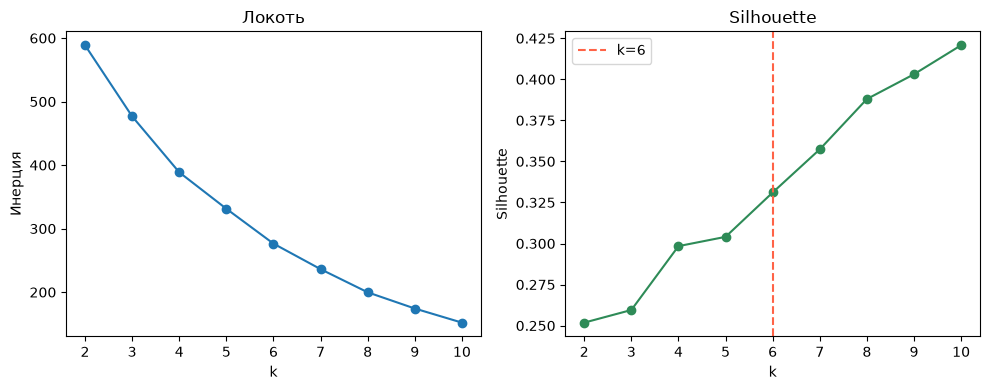

In [4]:
ks, inertias, silhouettes, best_k = choose_k(X)
for k, inertia, score in zip(ks, inertias, silhouettes):
    print(f"  k={k}  inertia={inertia:.1f}  silhouette={score:.3f}")
print("Выбранное k:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(ks, inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Инерция")
axes[0].set_title("Локоть")
axes[1].plot(ks, silhouettes, marker="o", color="seagreen")
axes[1].axvline(best_k, color="tomato", ls="--", label=f"k={best_k}")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
axes[1].legend()
axes[1].set_title("Silhouette")
fig.tight_layout()
fig.savefig(FIG / "01_choose_k.png", dpi=120, bbox_inches="tight")
plt.show()


## 4. Три алгоритма


DBSCAN eps=1.079
  KMeans           k=6 noise=0 sil=0.331 db=1.018 ch=73.5


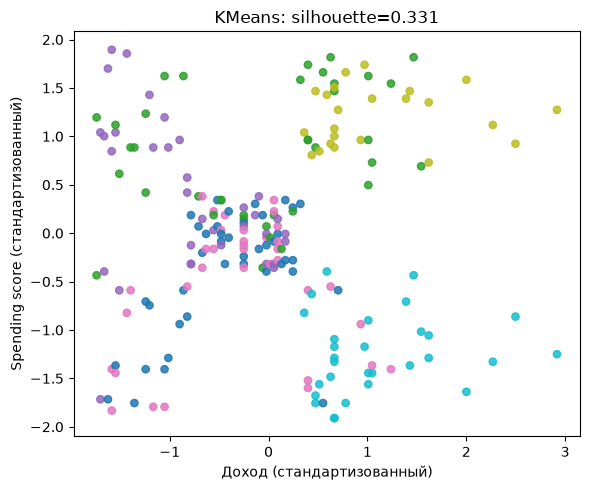

  Agglomerative    k=6 noise=0 sil=0.310 db=1.073 ch=70.2


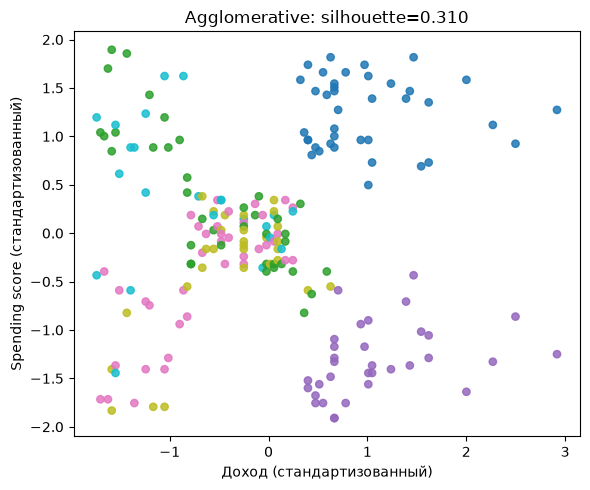

  DBSCAN           k=2 noise=7 sil=0.285 db=1.571 ch=67.5


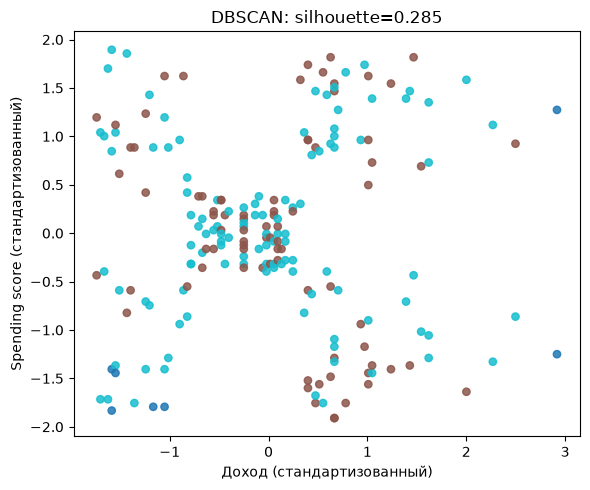


                silhouette  davies_bouldin  calinski_harabasz  n_clusters  n_noise
модель                                                                           
KMeans              0.331           1.018             73.496           6        0
Agglomerative       0.310           1.073             70.227           6        0
DBSCAN              0.285           1.571             67.452           2        7


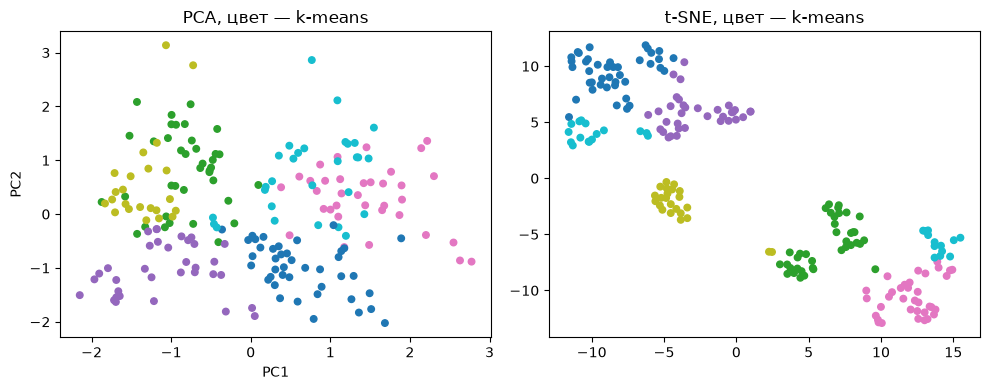


Графики: C:\WORK\MMO\lab7\figures


In [5]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
labels_km = kmeans.fit_predict(X)
labels_agg = AgglomerativeClustering(n_clusters=best_k).fit_predict(X)

min_samples = 5
eps = choose_dbscan_eps(X, min_samples=min_samples)
labels_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
print(f"DBSCAN eps={eps:.3f}")

results = {
    "KMeans": labels_km,
    "Agglomerative": labels_agg,
    "DBSCAN": labels_db,
}
rows = []
for name, labels in results.items():
    scores = cluster_scores(X, labels)
    rows.append({"модель": name, **scores})
    print(
        f"  {name:16s} k={scores['n_clusters']} noise={scores['n_noise']} "
        f"sil={scores['silhouette']:.3f} db={scores['davies_bouldin']:.3f} "
        f"ch={scores['calinski_harabasz']:.1f}"
    )
    scatter_clusters(
        X,
        labels,
        f"{name}: silhouette={scores['silhouette']:.3f}",
        FIG / f"02_scatter_{name.lower()}.png",
    )

summary = pd.DataFrame(rows).set_index("модель")
print("\n", summary.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap="tab10", s=22)
axes[0].set_title("PCA, цвет — k-means")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_km, cmap="tab10", s=22)
axes[1].set_title("t-SNE, цвет — k-means")
fig.tight_layout()
fig.savefig(FIG / "03_pca_tsne.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"\nГрафики: {FIG}")


## Выводы

Локоть инерции даёт около 6 групп. K-means чуть плотнее иерархии при том же числе групп. DBSCAN на этих данных видит меньше сгустков и несколько точек шума: между сегментами нет пустой полосы. Silhouette до k = 10 продолжает расти, поэтому максимум silhouette как число сегментов магазина не используется.
